# 🛑 Libraries

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt



---



In [2]:
from ucimlrepo import fetch_ucirepo
# fetch dataset
support2 = fetch_ucirepo(id=880)
# data (as pandas dataframes)
X = support2.data.features
y = support2.data.targets
# Assuming 'X' and 'y' are pandas DataFrames
# Concatenate horizontally (column-wise)
df = pd.concat([X, y], axis=1)


In [3]:
support2.variables

,name,role,type,demographic,description,units,missing_values
0,id,ID,Integer,None,None,None,no
1,age,Feature,Continuous,Age,Age of the patients in years,years,no
2,death,Target,Continuous,None,Death at any time up to National Death Index (...,None,no
3,sex,Feature,Categorical,Sex,Gender of the patient. Listed values are {male...,None,no
4,hospdead,Target,Binary,None,Death in hospital,None,no
5,slos,Other,Continuous,None,Days from Study Entry to Discharge,None,no
6,d.time,Other,Continuous,None,Days of follow-up,None,no
7,dzgroup,Feature,Categorical,None,The patient's disease sub category amogst ARF/...,None,no
8,dzclass,Feature,Categorical,None,"The patient's disease category amongst ""ARF/MO...",None,no
9,num.co,Feature,Continuous,None,The number of simultaneous diseases (or comorb...,None,no


In [4]:
df.shape
df.head(3)

,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,ph,glucose,bun,urine,adlp,adls,adlsc,death,hospdead,sfdm2
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,7.459961,NaN,NaN,NaN,7.0,7.0,7.0,0,0,NaN
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,7.250000,NaN,NaN,NaN,NaN,1.0,1.0,1,1,<2 mo. follow-up
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,7.459961,NaN,NaN,NaN,1.0,0.0,0.0,1,0,<2 mo. follow-up


- **ID column:**

To facilitate the manipulation of patient data, we will establish a unique identifier (ID) for each patient. This will allow us to keep track of the information associated with each patient within the dataset in a more organized and accurate manner.

In [5]:
df['ID'] = df.index
df.set_index('ID', inplace=True)
df.head(3)

,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,ph,glucose,bun,urine,adlp,adls,adlsc,death,hospdead,sfdm2
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,7.459961,NaN,NaN,NaN,7.0,7.0,7.0,0,0,NaN
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,7.250000,NaN,NaN,NaN,NaN,1.0,1.0,1,1,<2 mo. follow-up
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,7.459961,NaN,NaN,NaN,1.0,0.0,0.0,1,0,<2 mo. follow-up


# 🛑 Data Cleaning

Analyse the data in you dataset, provide a statistichal analysis, visualizations...

Clean and prepare the data, use the different methods seen in class.

- **COR PLOT:**

We are going to create a correlation plot (cor plot) of the variables to identify the linear relationships between them. This will allow us to visualize the magnitude and direction of the correlations (positive or negative) between the variables, thus facilitating the interpretation of their interdependence and helping us to detect patterns or possible collinearities in the data set, which can be useful in data cleaning.

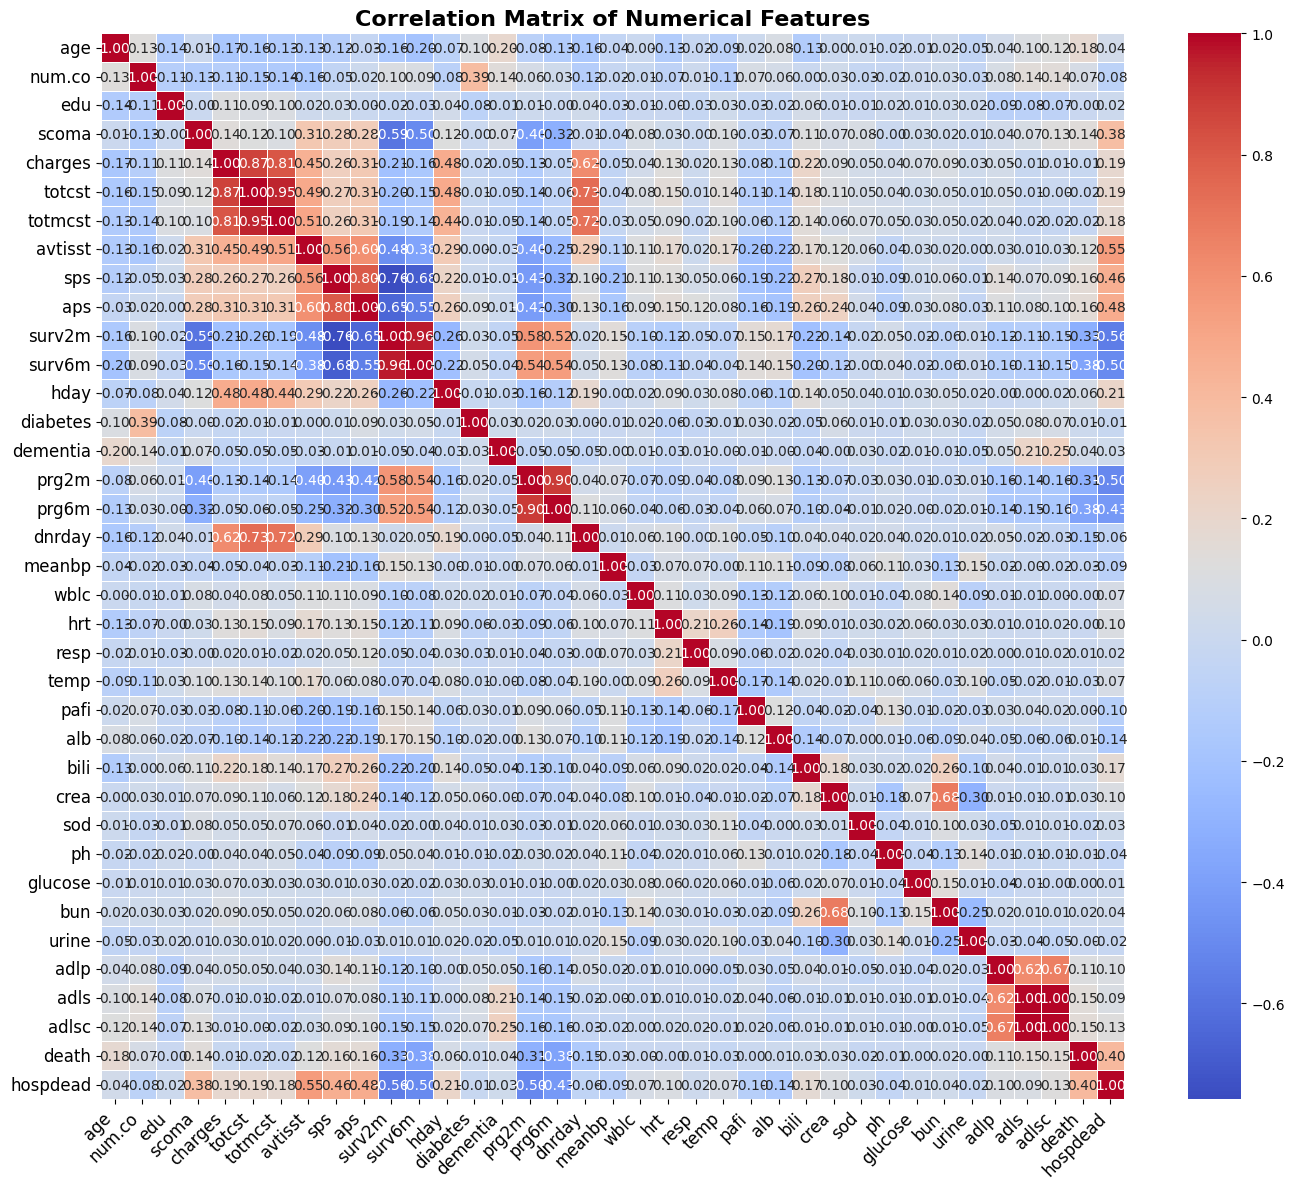

In [6]:
# Select just the numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns
correlation_matrix = df[numerical_cols].corr()

# Create the heatmap of the correlation matrix
plt.figure(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    annot=True,            # Show values in each cell
    cmap='coolwarm',       # Color pallete
    fmt=".2f",             # Numerical value format
    linewidths=0.5,        # Width of dividing lines
    annot_kws={"size": 10} # Annotation font size
)

# Improve visualization
plt.xticks(rotation=45, ha='right', fontsize=12)  # Rotation and alignment of labels on the x-axis
plt.yticks(rotation=0, fontsize=12)               # Labels on the y-axis
plt.title('Correlation Matrix of Numerical Features', fontsize=16, weight='bold') # Title

# Show the graph
plt.tight_layout()  # Adjust the layout to prevent labels from overlapping
plt.show()

We obtain the number of rows that have at least one missing value (NA) to assess data quality and determine the number of incomplete records. This will allow us to decide on possible imputation or data cleaning strategies before proceeding with the analysis.

In [7]:
num_filas_con_na_p0 = df.isna().any(axis=1).sum()
print(f"The number of rows with at least one NA value is:{num_filas_con_na_p0}, the percentage of rows with na's is {(num_filas_con_na_p0/df.shape[0])*100}")

The number of rows with at least one NA value is:8799, the percentage of rows with na's is 96.63920922570016


We will create a specific dataset to determine the reduction of missing values ​​(NAs) and analyze the variation in the data dimension after applying each data cleaning process. This dataset will allow us to evaluate how the manipulation of the NAs affects the amount of missing values ​​and how it influences the overall structure of the dataset, helping us to better understand the impact of these processes on the subsequent analysis.

In [8]:
data_cleaning_evaluation= pd.DataFrame()
new_row = pd.DataFrame({
    'Phase': [0],
    'Atleast_1NA': [num_filas_con_na_p0],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)



- **Phase 1:**
The metadata tells us that the columns `'scoma'`, `'surv2m'`, `'surv6m'`, `'prg2m'` and `'prg6m'` contain values ​​generated by models. Since we are only interested in real data obtained directly by specialists, we are going to exclude these columns from the analysis to avoid the use of artificial values ​​and focus on the authentic information in the dataset. However, we will store these columns in another dataset, since we have created a unique ID per user, which will make future manipulation easier. This way, if in the future the columns generated by the models are of interest to us, we will be able to use them and compare the results obtained by our models with those generated by previous models.

In [9]:
# List of columns to separate and store in another DataFrame
generated_columns = ['scoma', 'surv2m', 'surv6m', 'prg2m', 'prg6m', 'dnr', 'dnrday','aps', 'sps',]

# Create a new DataFrame with just the selected columns
df_generated = df[generated_columns]

# Remove the selected columns from the original DataFrame
df = df.drop(columns=generated_columns)


1. **Patient survival and interview**: The patient survived for 2 months to complete the 2-month follow-up interview, which showed no signs of moderate to severe functional disability.

2. **Inability to perform activities of daily living (ADLs)**: At 2 months post-study entry, the patient was unable to perform 4 or more ADLs. If the patient was unavailable for an interview and a surrogate was interviewed instead, disability was defined as an ADL score ≥ 5.

3. **Sickness Impact Profile (SIP)**: The total SIP score at 2 months was ≥ 30.

4. **Intubation or coma**: The patient was either intubated or in a coma at the 2-month mark.

5. **Death**: The patient died within 2 months of study entry.

**Note**: There are 159 patients who survived for 2 months but for whom there were no patient or surrogate interviews. These patients have missing SFDM2 data. THESE PATIENTS WILL BE GROUP 0

In [10]:
df['sfdm2'].fillna(0, inplace=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/1801257064.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['sfdm2'].fillna(0, inplace=True)


In [11]:
num_filas_con_na_p1 = df.isna().any(axis=1).sum()
print(f"The number of rows with at least one NA value is:{num_filas_con_na_p1}, the percentage of rows with na's is {(num_filas_con_na_p1/df.shape[0])*100}")

The number of rows with at least one NA value is:8733, the percentage of rows with na's is 95.91433278418452


In [12]:
new_row = pd.DataFrame({
    'Phase': [1],
    'Atleast_1NA': [num_filas_con_na_p1],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 2:**
In phase 2, we will visualize the missing values ​​(NA's) by column. This will allow us to identify which variables have missing data and determine the extent of missing values ​​in the dataset. In addition, we will determine the imputation values ​​suggested by the metadata, which will help us decide how to proceed with replacing missing values ​​in the following stages of the analysis. It is important to note that this imputation process can decrease data variability, since replacing missing values ​​with estimates could reduce the natural dispersion of the variables.

Text(0, 0.5, 'Number of Missing Values')

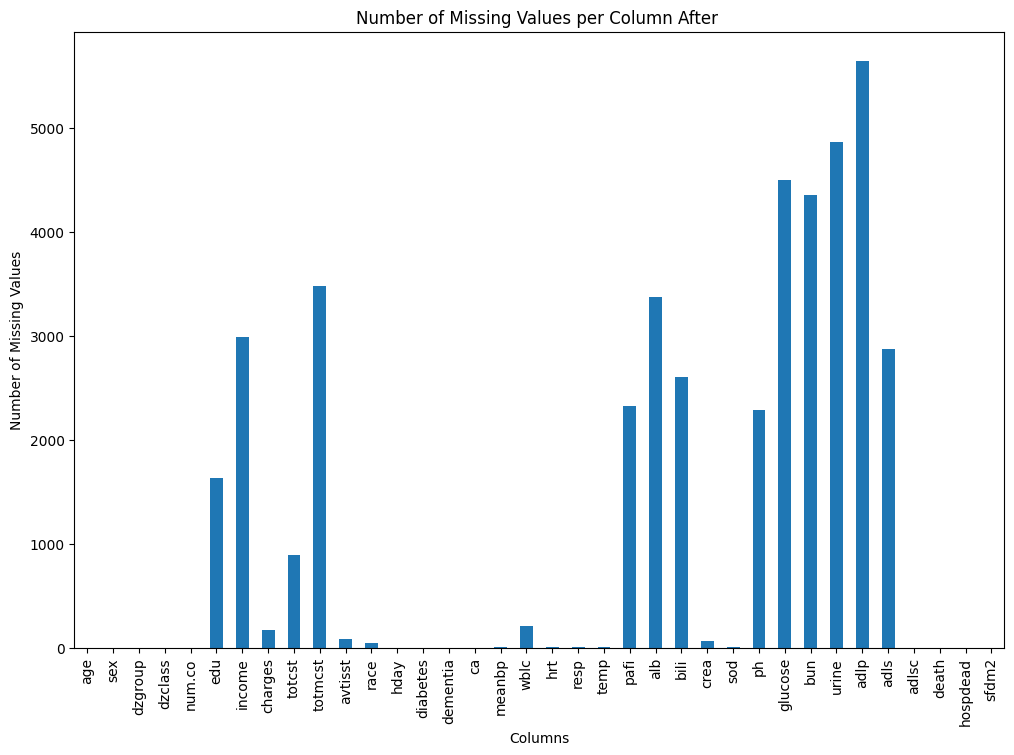

In [13]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After ')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

- **Dataset Imputation Metadata**

The dataset metadata indicates that no preprocessing was applied, but imputation is recommended due to a high percentage of missing values. Suggested imputation values are as follows:

- **Serum Albumin** (`alb`): 3.5
- **PaO2/FiO2 Ratio** (`pafi`): 333.3
- **Bilirubin** (`bili`): 1.01
- **Creatinine** (`crea`): 1.01
- **Blood Urea Nitrogen** (`bun`): 6.51
- **White Blood Cell Count** (`wblc`): 9 (thousands)
- **Urine Output** (`urine`): 2502

These recommended values are baseline fill-ins for missing data in the respective physiological variables.


Text(0, 0.5, 'Number of Missing Values ')

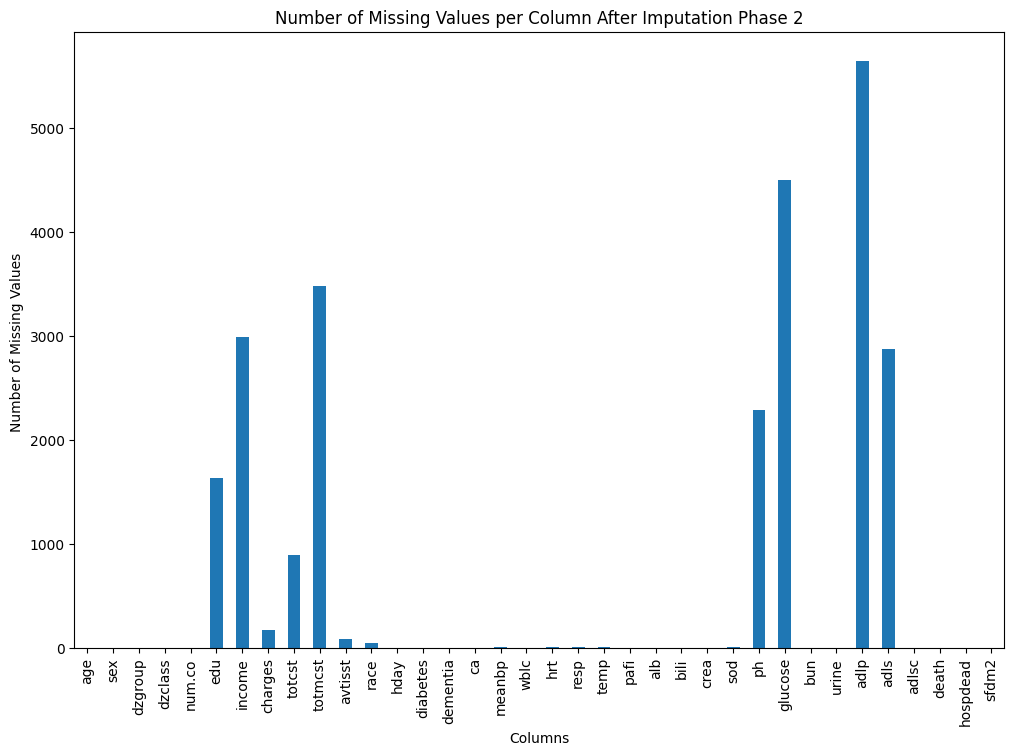

In [14]:
impute_values = {
    'alb': 3.5,
    'pafi': 333.3,
    'bili': 1.01,
    'crea': 1.01,
    'bun': 6.51,
    'wblc': 9,
    'urine': 2502
}

df.fillna(value=impute_values, inplace=True)
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Imputation Phase 2')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values ')

In [15]:
num_filas_con_na_p2 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p2}, the percentage of rows with na's is {(num_filas_con_na_p2/df.shape[0])*100}")

Number of rows with at least one NA: 8425, the percentage of rows with na's is 92.53157605711148


In [16]:
new_row = pd.DataFrame({
    'Phase': [2],
    'Atleast_1NA': [num_filas_con_na_p2],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 3:**
  
  Since there are columns with less than 100 missing values ​​(NA's), we will remove the rows that present these missing values. The data loss will be minimal, since we are talking about a reduction of 1-2% of the total data, which will not substantially affect the overall variability of the data set. This removal will allow us to maintain the integrity of the data without compromising the quality of the analysis.

In [17]:
# Count the values of NA per column
df_na_count = df.isna().sum()

# Filter the columns with less than 100 NAs
columns_with_less_than_100_na = df_na_count[df_na_count < 100]

# Obtain the names of the columns instead of the counts
columns_to_drop_na = columns_with_less_than_100_na.index.tolist()

# Sum the NA values of those columns
total_na_in_filtered_columns = columns_with_less_than_100_na.sum()

# Remove the rows containing NAs just in those specified columns
# Use 'columns_to_drop_na' which contains the column names
df.dropna(subset=columns_to_drop_na, inplace=True)


print(f"Total number of NaNs in filtered columns: {total_na_in_filtered_columns}")


Total number of NaNs in filtered columns: 129


Text(0, 0.5, 'Number of Missing Values ')

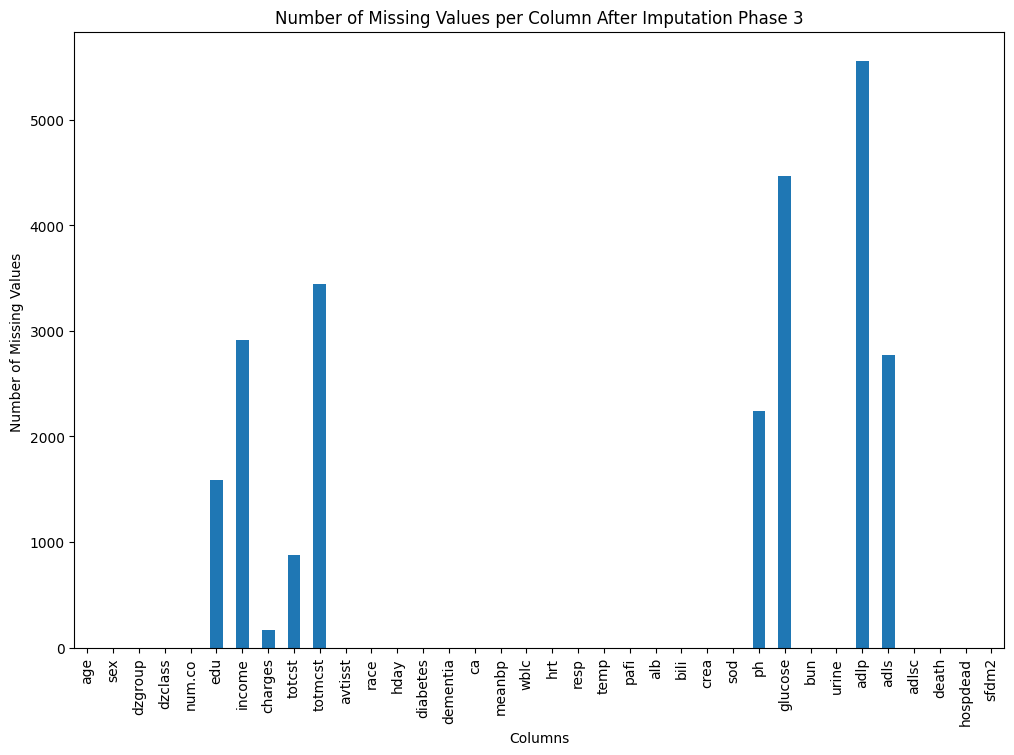

In [18]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Imputation Phase 3')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values ')

In [19]:
num_filas_con_na_p3 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p3}, the percentage of rows with na's is {(num_filas_con_na_p3/df.shape[0])*100}")

Number of rows with at least one NA: 8300, the percentage of rows with na's is 92.42761692650335


In [20]:
new_row = pd.DataFrame({
    'Phase': [3],
    'Atleast_1NA': [num_filas_con_na_p3],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 4-5: Missing Values Providing Valuable Information**

In the dataset `df`, certain columns with missing values might provide valuable insights rather than just being "missing data." Specifically, the following columns:

- **edu** (Education level)
- **income** (Income level)

In the case of **edu** (Education level) and **income** (Income level), missing values might reflect socio-economic factors. For example, missing data in the `income` column may indicate a certain socio-economic group that is not willing to disclose their income level, and missing values in `edu` could suggest patients who do not wish to share their educational background.

Thus, it's important to treat these missing values with care, as they may provide important context and insights into the patient’s privacy concerns and social behavior.


- **Phase 4: Income Analysis**

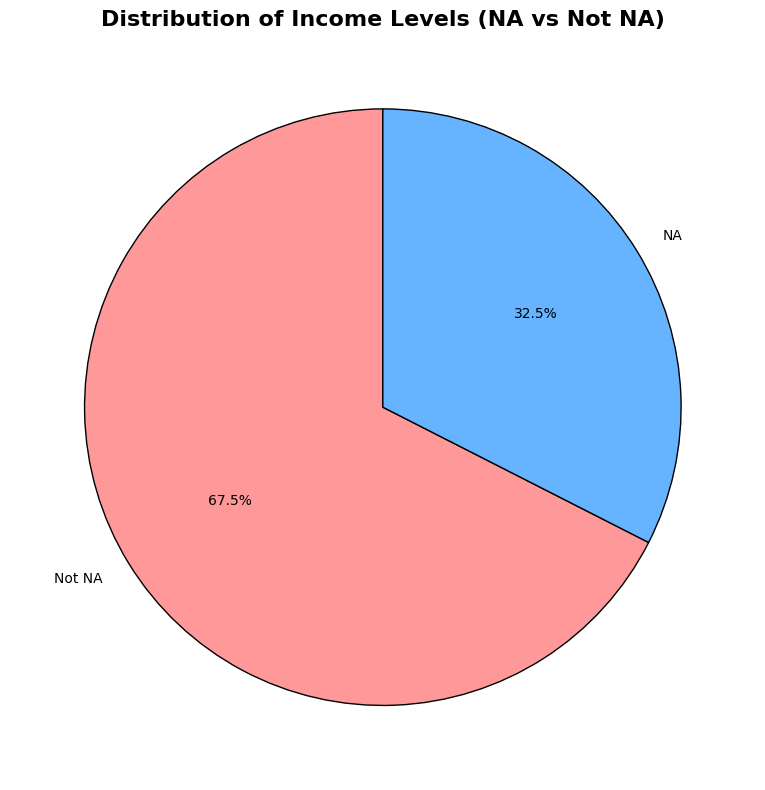

In [21]:
# Create a new column categorizing 'income' as 'NA' or 'Not NA'
income_status = df['income'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
income_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of Income Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

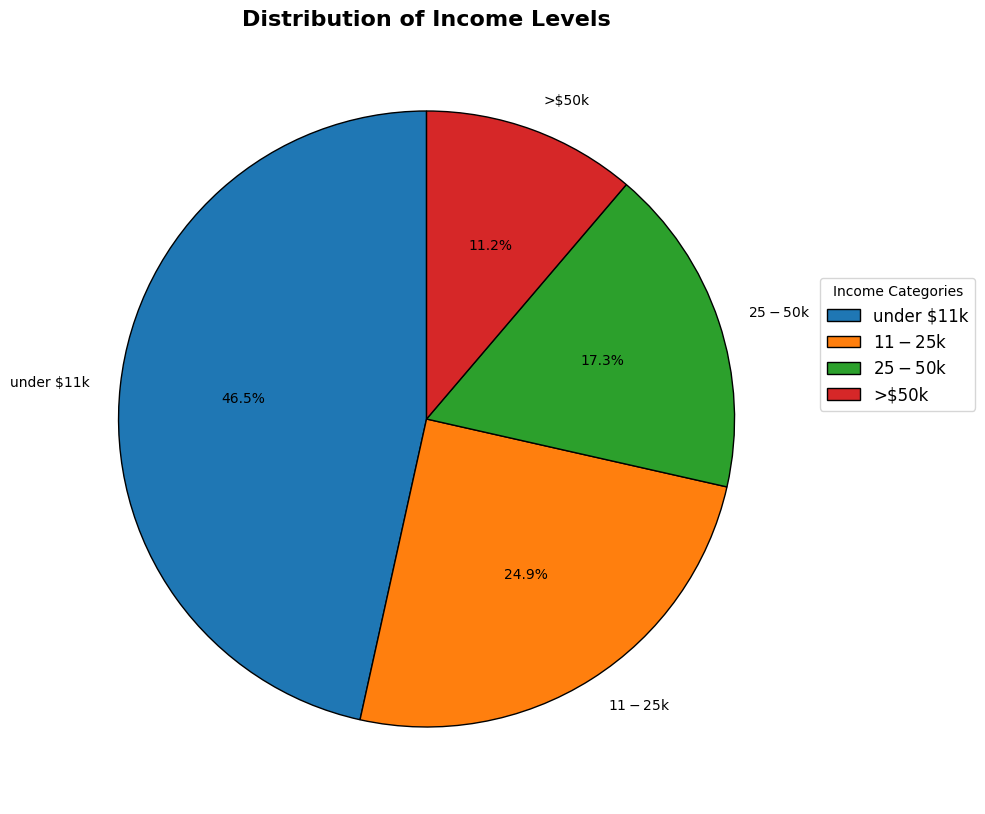

In [22]:
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
ax = df['income'].value_counts().plot(kind='pie',
                                                   autopct='%1.1f%%',
                                                   startangle=90,  # Rotate to start from top
                                                   wedgeprops={'edgecolor': 'black', 'linewidth': 1},
                                                   figsize=(10, 10))

# Make the chart more readable and visually appealing
plt.title('Distribution of Income Levels', fontsize=16, weight='bold')
plt.ylabel('')  # Hide y-axis label to clean up the chart

# Add a legend (optional but helpful for clarity)
plt.legend(title='Income Categories', loc='lower left', bbox_to_anchor=(1, 0.5), fontsize=12)


In [23]:
# Replace NaN values in the 'income' column with 'Unknown'
df['income'].fillna('Unknown', inplace=True)


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/1123428881.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['income'].fillna('Unknown', inplace=True)


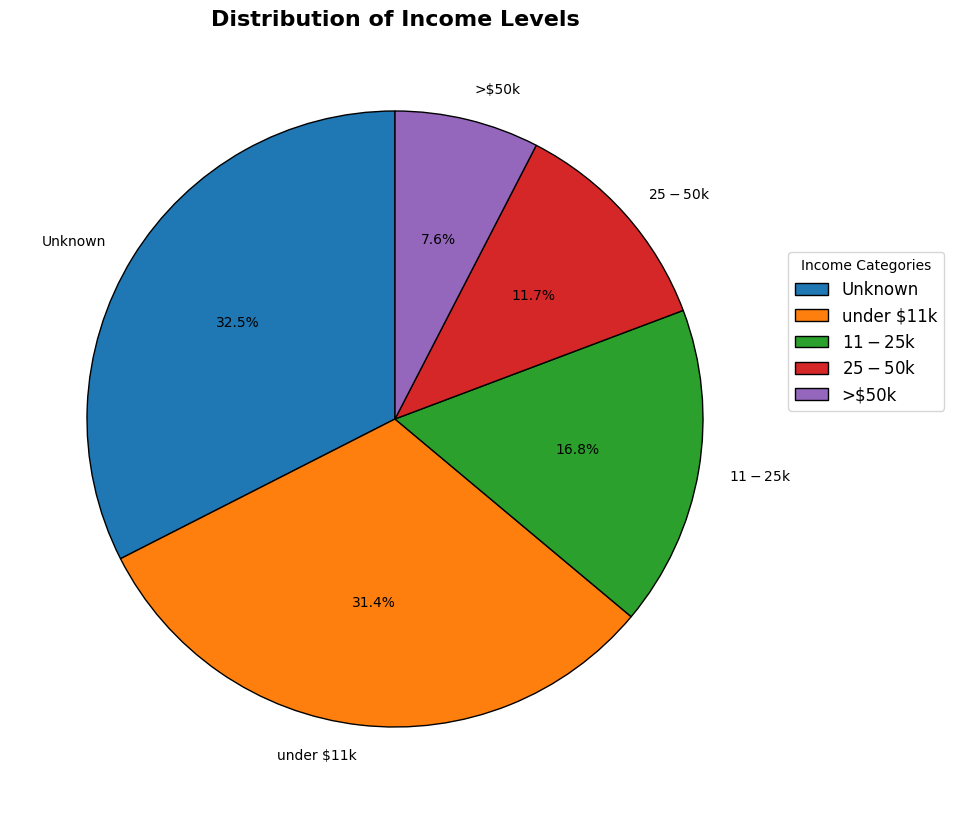

In [24]:
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
ax = df['income'].value_counts().plot(kind='pie',
                                                   autopct='%1.1f%%',
                                                   startangle=90,  # Rotate to start from top
                                                   wedgeprops={'edgecolor': 'black', 'linewidth': 1},
                                                   figsize=(10, 10))

# Make the chart more readable and visually appealing
plt.title('Distribution of Income Levels', fontsize=16, weight='bold')
plt.ylabel('')  # Hide y-axis label to clean up the chart

# Add a legend (optional but helpful for clarity)
plt.legend(title='Income Categories', loc='lower left', bbox_to_anchor=(1, 0.5), fontsize=12)


Text(0, 0.5, 'Number of Missing Values')

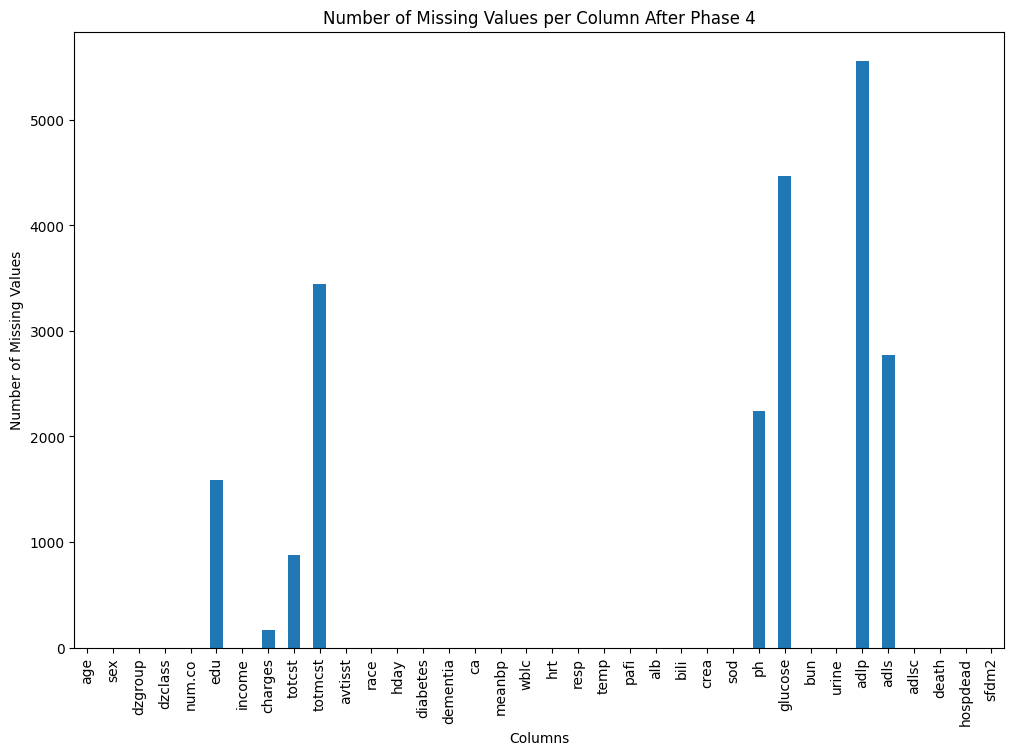

In [25]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Phase 4')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [26]:
num_filas_con_na_p4 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p4}, the percentage of rows with na's is {(num_filas_con_na_p4/df.shape[0])*100}")

Number of rows with at least one NA: 8129, the percentage of rows with na's is 90.52338530066815


In [27]:
new_row = pd.DataFrame({
    'Phase': [4],
    'Atleast_1NA': [num_filas_con_na_p4],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 5: Edu**

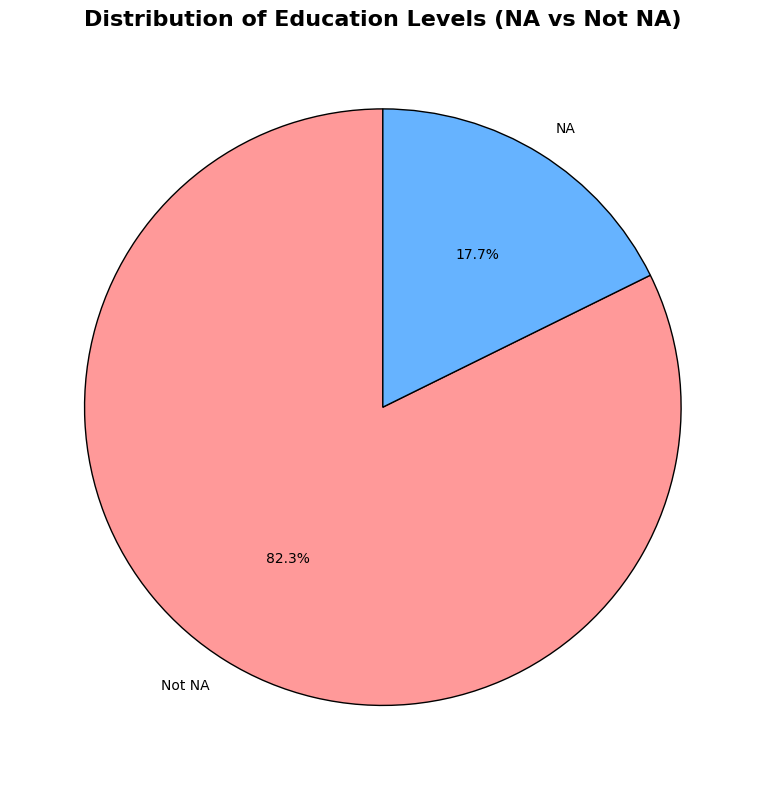

In [28]:
# Create a new column categorizing 'edu' as 'NA' or 'Not NA'
edu_status = df['edu'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
edu_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of Education Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

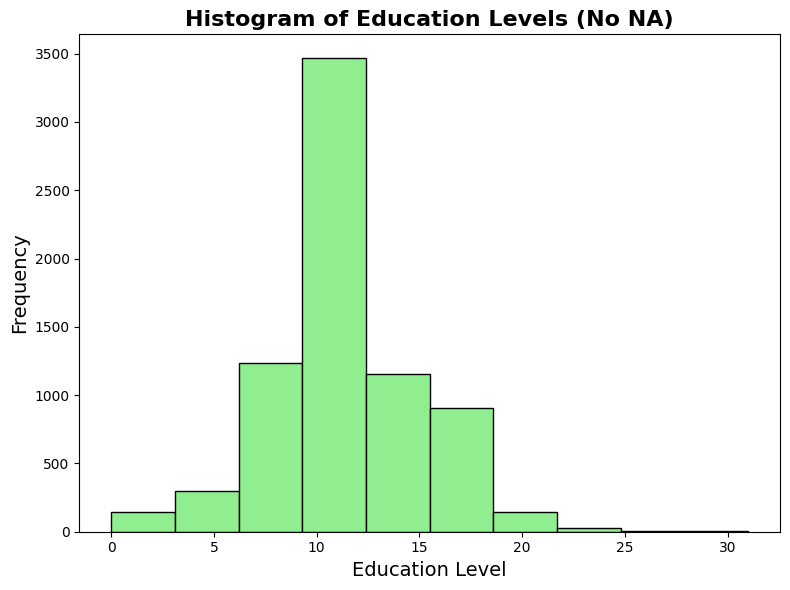

In [29]:
plt.figure(figsize=(8, 6))  # Adjust the figure size as needed
plt.hist(df['edu'].dropna(), color='lightgreen', edgecolor='black')

# Add title and labels
plt.title('Histogram of Education Levels (No NA)', fontsize=16, weight='bold')
plt.xlabel('Education Level', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

# Show the plot
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of Missing Values')

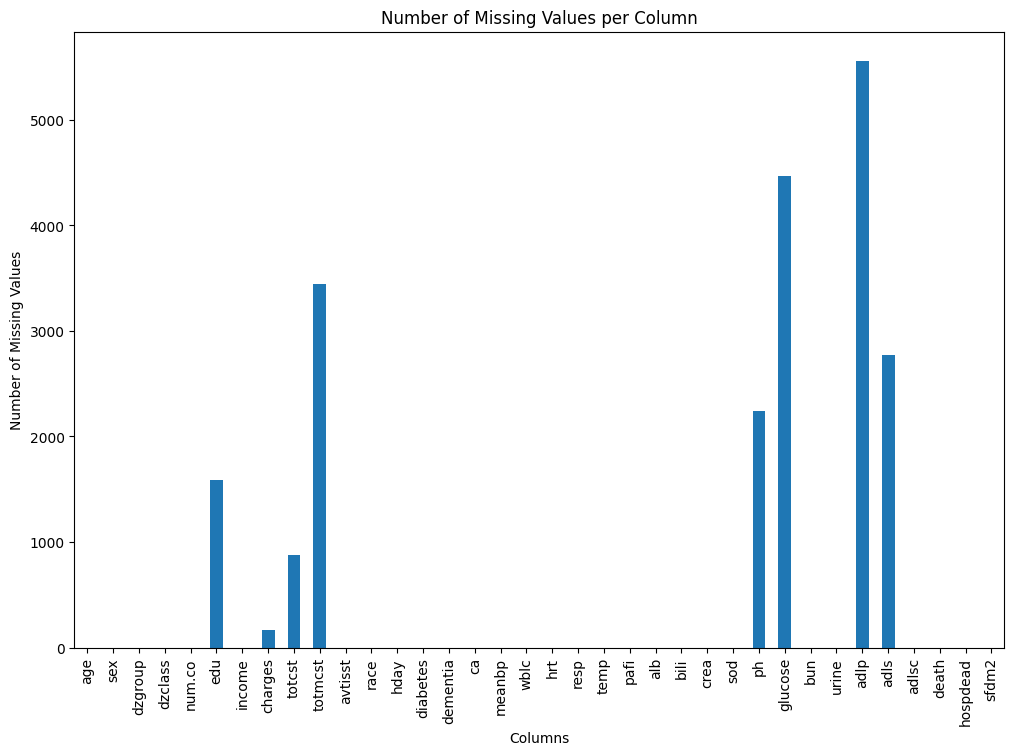

In [30]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

**NA's edu columns cleaning using the mean of the column**

We have decided to use the mean to fill the missing values, considering the distribution of the non-missing data and the relatively low percentage of missing values. However, we are aware that this approach reduces the variability of the data and may affect the accuracy of the results.

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/789215640.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['edu'].fillna(mean_edu, inplace=True)


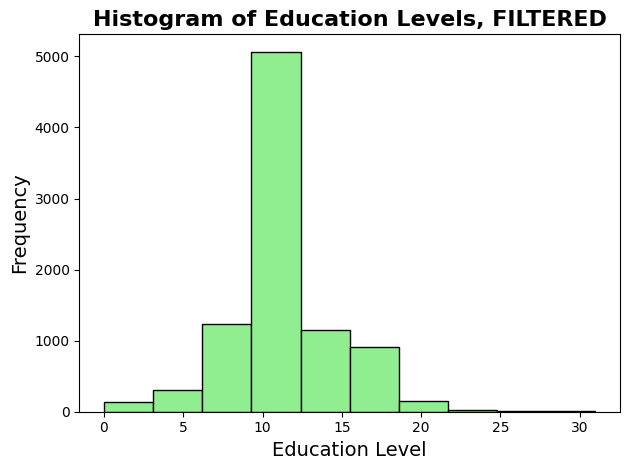

In [31]:
# Calculate the mean of the 'edu' column, excluding NA values
mean_edu = df['edu'].mean()
# Fill NA values in the 'edu' column with the calculated mean
df['edu'].fillna(mean_edu, inplace=True)

plt.hist(df['edu'], color='lightgreen', edgecolor='black')

# Add title and labels
plt.title('Histogram of Education Levels, FILTERED', fontsize=16, weight='bold')
plt.xlabel('Education Level', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

# Show the plot
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of Missing Values')

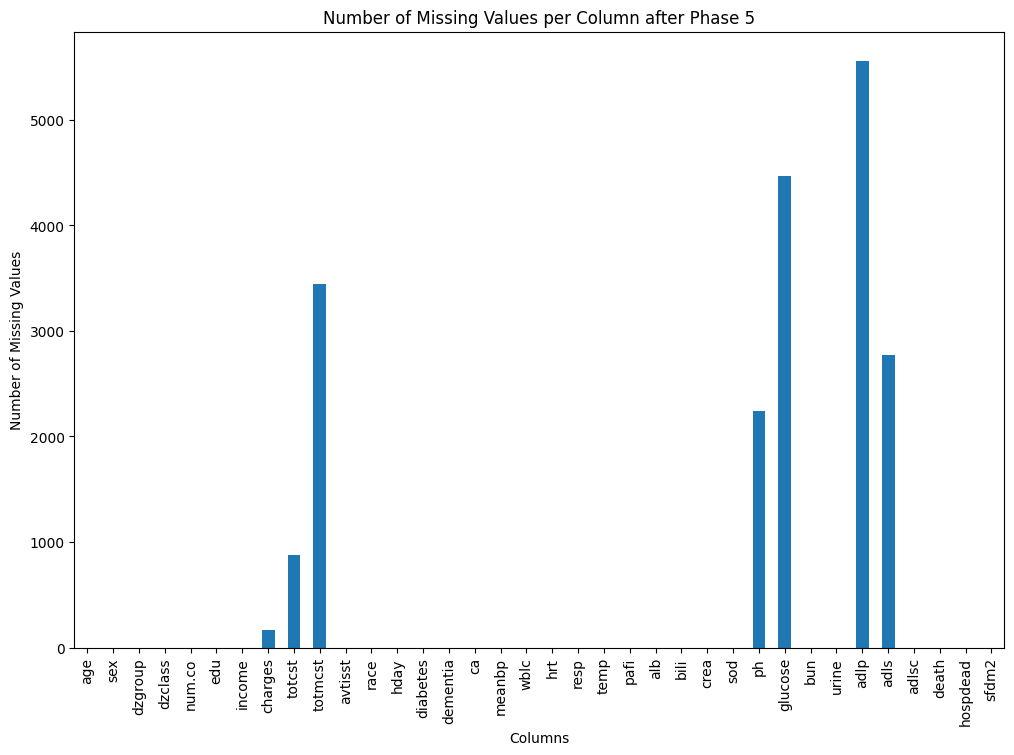

In [32]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column after Phase 5')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [33]:
num_filas_con_na_p5 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p5}, the percentage of rows with na's is {(num_filas_con_na_p5/df.shape[0])*100}")

Number of rows with at least one NA: 8108, the percentage of rows with na's is 90.28953229398664


In [34]:
new_row = pd.DataFrame({
    'Phase': [5],
    'Atleast_1NA': [num_filas_con_na_p5],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 6: ADLP and ADLS cleaning**

  - **ADLP**

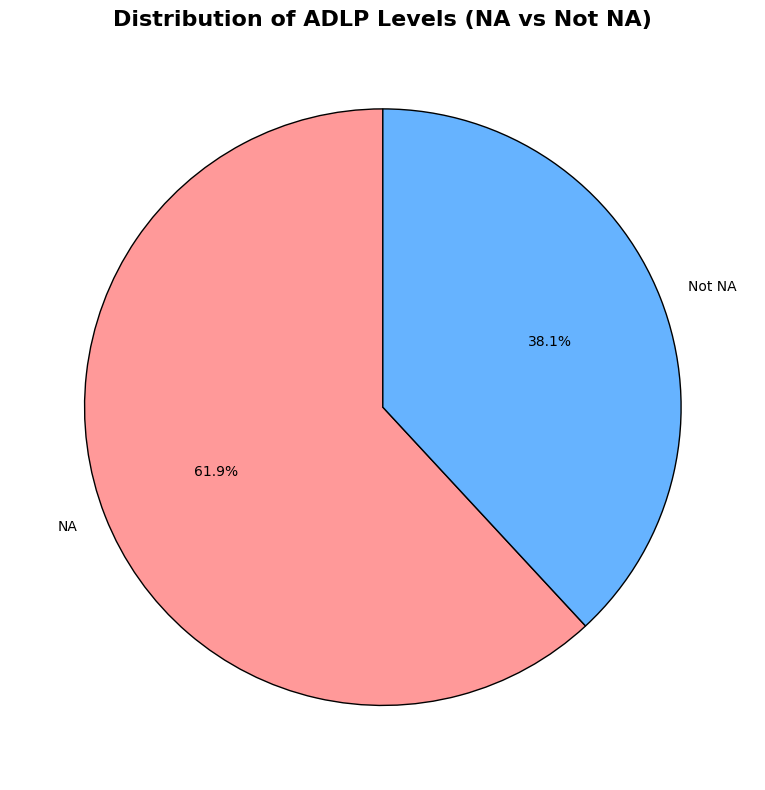

In [35]:
# Create a new column categorizing 'adlp' as 'NA' or 'Not NA'
adlp_status = df['adlp'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
adlp_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of ADLP Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

- **ADLS**

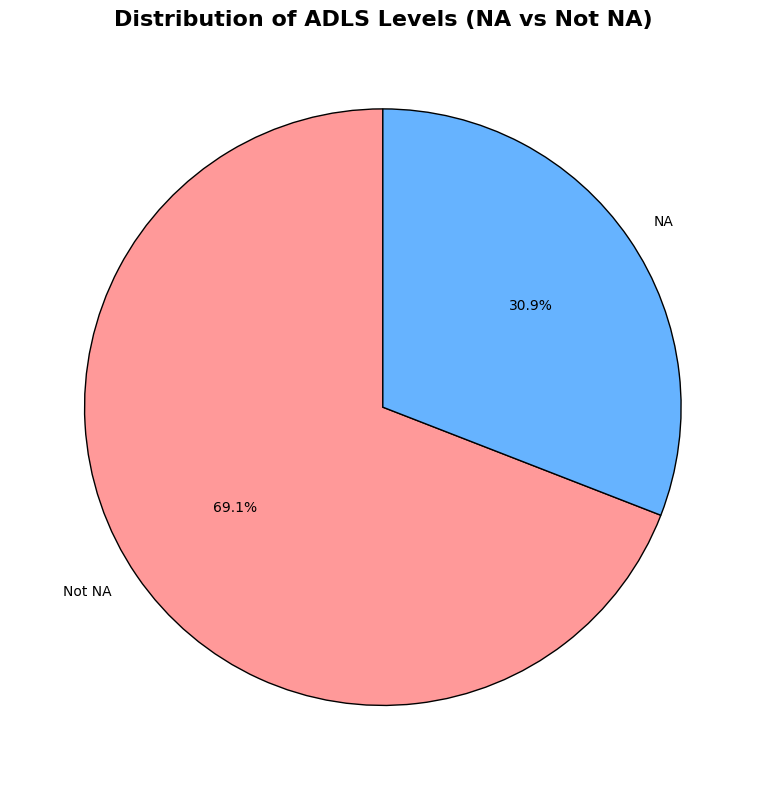

In [36]:
# Create a new column categorizing 'adls' as 'NA' or 'Not NA'
adls_status = df['adls'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
adls_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of ADLS Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

In [37]:
df[['adls','adlp']].describe()

,adls,adlp
count,6205.000000,3422.000000
mean,1.638195,1.163939
std,2.231621,1.743995
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.000000
75%,3.000000,2.000000
max,7.000000,7.000000


In [38]:
# Calculate the Pearson correlation coefficient
correlation_coefficient = df['adls'].corr(df['adlp'])

print(f"The Pearson correlation coefficient between 'adls' and 'adlp' is: {correlation_coefficient}")

The Pearson correlation coefficient between 'adls' and 'adlp' is: 0.6196226699037741


In [39]:
# Remove the rows with NAs
df_cleaned = df.dropna(subset=['adlp', 'adls'])

# Perform the Mann-Whitney U test
u_stat, p_value = stats.mannwhitneyu(df_cleaned['adlp'], df_cleaned['adls'])

# Print the results
print(f'U statistic: {u_stat}')
print(f'p-value: {p_value}')

# Interpretation of the p value
alpha = 0.05
if p_value < alpha:
    print("The groups are significantly different.")
else:
    print("There is no significant difference between the groups.")

U statistic: 3451292.0
p-value: 0.4764634008549511
There is no significant difference between the groups.


The columns `adls` and `adlp` contain the same values, according to the metadata, but they differ in that one is associated with the value determined by the patient and the other with the value determined by a relative. The Pearson ratio between both columns is 0.62, which indicates a moderate correlation. However, to avoid a conceptual error when merging them, we have decided to perform a test to see if there is a significant difference between the means of the two groups (patient and relative). This will allow us to determine if it is appropriate to merge the columns without losing the validity of the information.

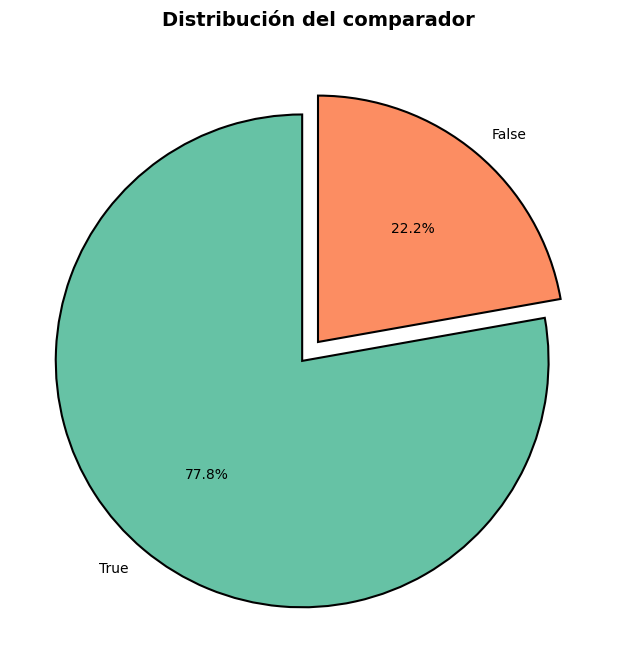

In [40]:
data_aldps=df[['adls','adlp']]
# Create a new column 'comparador' based on the condition
comparador = data_aldps.apply(lambda row: (row.notna().sum() >= 1), axis=1)
# Count the values of the 'comprador' for the pie chart
comparador_counts = comparador.value_counts()

plt.figure(figsize=(8, 8))  # Larger figure for better visibility
plt.pie(comparador_counts,
        labels=['True', 'False'],
        autopct='%1.1f%%',
        startangle=90,
        colors=['#66c2a5', '#fc8d62'],
        wedgeprops={'edgecolor': 'black', 'linewidth': 1.5},
        explode=(0.1, 0))

# Add title
plt.title('Distribución del comparador', fontsize=14, weight='bold')

# Display the chart
plt.show()

In [41]:
# Calcular la media de las columnas, ignorando NaN
media_columnas = df[['adls', 'adlp']].mean(axis=1)

# Combinar las columnas usando operaciones vectorizadas
df['Adls_Adlp_merge'] = np.where(
    df['adls'].notna() & df['adlp'].notna(), media_columnas,   # Caso 1: Ambos valores presentes, tomar la media
    np.where(df['adls'].notna(), df['adls'],                    # Caso 2: Solo 'columna1' tiene valor
             np.where(df['adlp'].notna(), df['adlp'], np.nan))  # Caso 3: Solo 'columna2' tiene valor o ambos son NaN
)

# Eliminar las columnas originales
df.drop(['adls', 'adlp'], axis=1, inplace=True)



In [42]:
mean_Adls_Adlp = df['Adls_Adlp_merge'].mean()
df['Adls_Adlp_merge'].fillna(mean_Adls_Adlp, inplace=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/97905108.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Adls_Adlp_merge'].fillna(mean_Adls_Adlp, inplace=True)


Text(0, 0.5, 'Number of Missing Values')

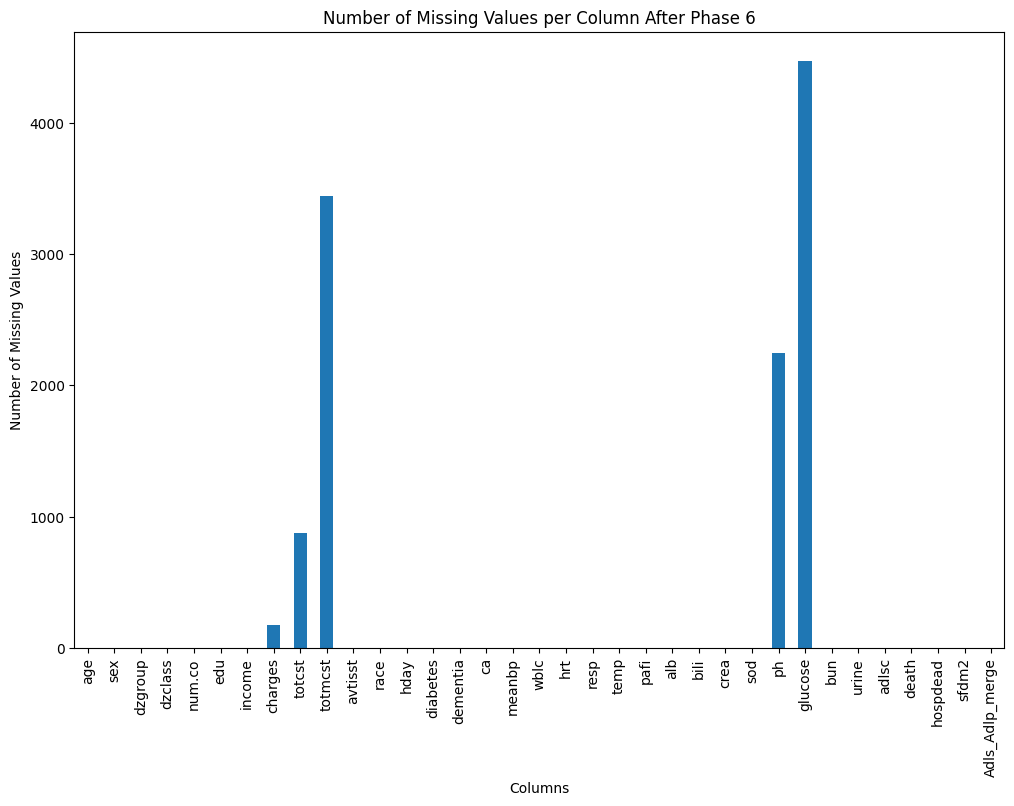

In [43]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Phase 6')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [44]:
num_filas_con_na_p6 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p6}, the percentage of rows with na's is {(num_filas_con_na_p6/df.shape[0])*100}")

Number of rows with at least one NA: 6176, the percentage of rows with na's is 68.7750556792873


In [45]:
new_row = pd.DataFrame({
    'Phase': [6],
    'Atleast_1NA': [num_filas_con_na_p6],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 7: totcst/totmcst**


In [46]:
# Calculate the Pearson correlation coefficient
correlation_coefficient = df['totcst'].corr(df['totmcst'])

print(f"The Pearson correlation coefficient between 'totcst' and 'totmcst' is: {correlation_coefficient}")

The Pearson correlation coefficient between 'totcst' and 'totmcst' is: 0.9487083972166727


In [47]:
# Eliminar las filas con NaN
df_cleaned = df.dropna(subset=['totcst', 'totmcst'])

# Realizar la prueba de Mann-Whitney U
u_stat, p_value = stats.mannwhitneyu(df_cleaned['totmcst'], df_cleaned['totcst'])

# Imprimir los resultados
print(f'U statistic: {u_stat}')
print(f'p-value: {p_value}')

# Interpretación del valor p
alpha = 0.05
if p_value < alpha:
    print("The groups are significantly different.")
else:
    print("There is no significant difference between the groups.")

U statistic: 15058685.0
p-value: 0.10781563053020059
There is no significant difference between the groups.


In [48]:
df = df.drop(columns='totmcst')

In [49]:
mean_totcst= df['totcst'].mean()
df['totcst'].fillna(mean_totcst, inplace=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/3351172924.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['totcst'].fillna(mean_totcst, inplace=True)


Text(0, 0.5, 'Number of Missing Values')

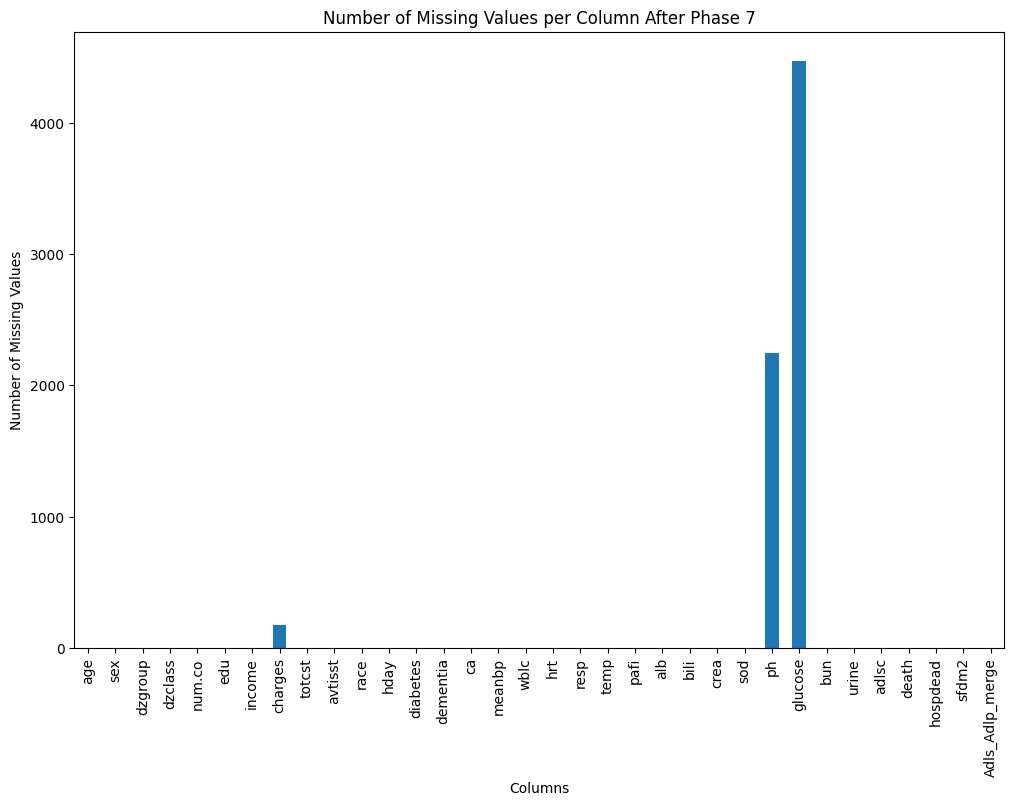

In [50]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Phase 7')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [51]:
num_filas_con_na_p7 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p7}, the percentage of rows with na's is {(num_filas_con_na_p7/df.shape[0])*100}")

Number of rows with at least one NA: 5645, the percentage of rows with na's is 62.8619153674833


In [52]:
new_row = pd.DataFrame({
    'Phase': [7],
    'Atleast_1NA': [num_filas_con_na_p7],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 8: Charges**

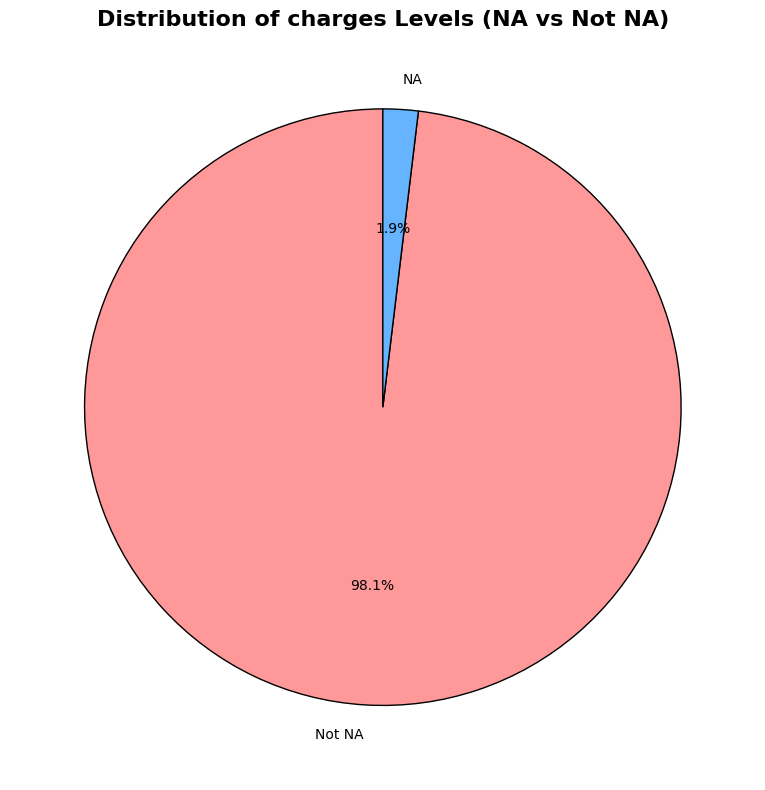

In [53]:
# Create a new column categorizing charges as 'NA' or 'Not NA'
charges_status = df['charges'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
charges_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of charges Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

Given the low percentage of missing values ​​(NaN) in this column, we have decided to remove the rows containing these values. This is because, since the amount of data we would lose is minimal, we seek to maintain the quality and reliability of the data for subsequent analysis without compromising the accuracy of the results.

In [54]:
df=df.dropna(subset=['charges'])

Text(0, 0.5, 'Number of Missing Values')

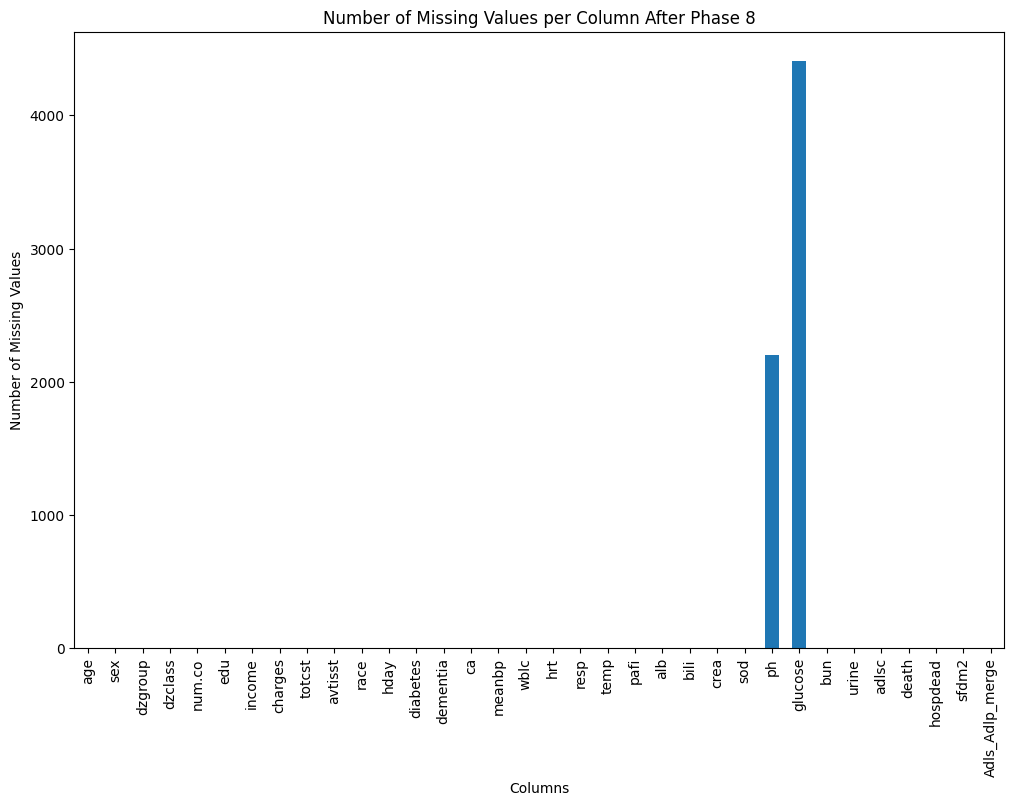

In [55]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Phase 8')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [56]:
num_filas_con_na_p8 = df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p8}, the percentage of rows with na's is {(num_filas_con_na_p8/df.shape[0])*100}")

Number of rows with at least one NA: 5474, the percentage of rows with na's is 62.14099216710183


In [57]:
new_row = pd.DataFrame({
    'Phase': [8],
    'Atleast_1NA': [num_filas_con_na_p8],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

- **Phase 9: PH**

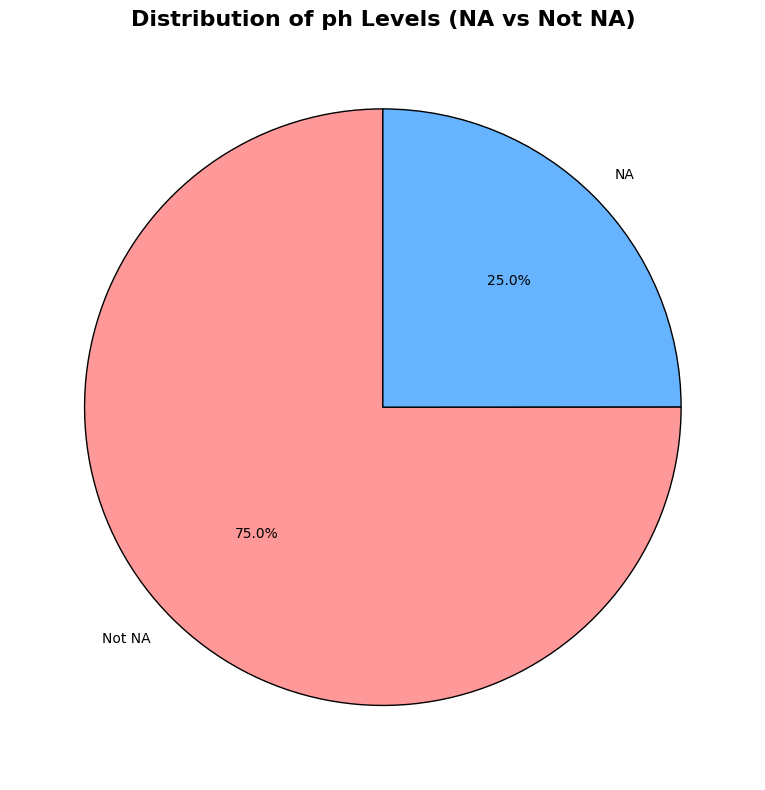

In [58]:
ph_status = df['ph'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
ph_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of ph Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

Since the numerical column presents 25% missing values ​​(NA's), we have decided to impute the missing values ​​with the mean. This approach assumes that the missing values ​​will be replaced by the average of the available data, which provides a representative estimate without introducing significant bias. With 25% missing data, the mean is a reliable method, as it maintains the original distribution of the data without drastically altering it. Furthermore, this method is simple to apply and ensures that the subsequent analysis is more consistent, without significantly affecting the variability of the data.

In [59]:
mean_ph= df['ph'].mean()
df['ph'].fillna(mean_ph, inplace=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_34501/196797528.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ph'].fillna(mean_ph, inplace=True)


Text(0, 0.5, 'Number of Missing Values')

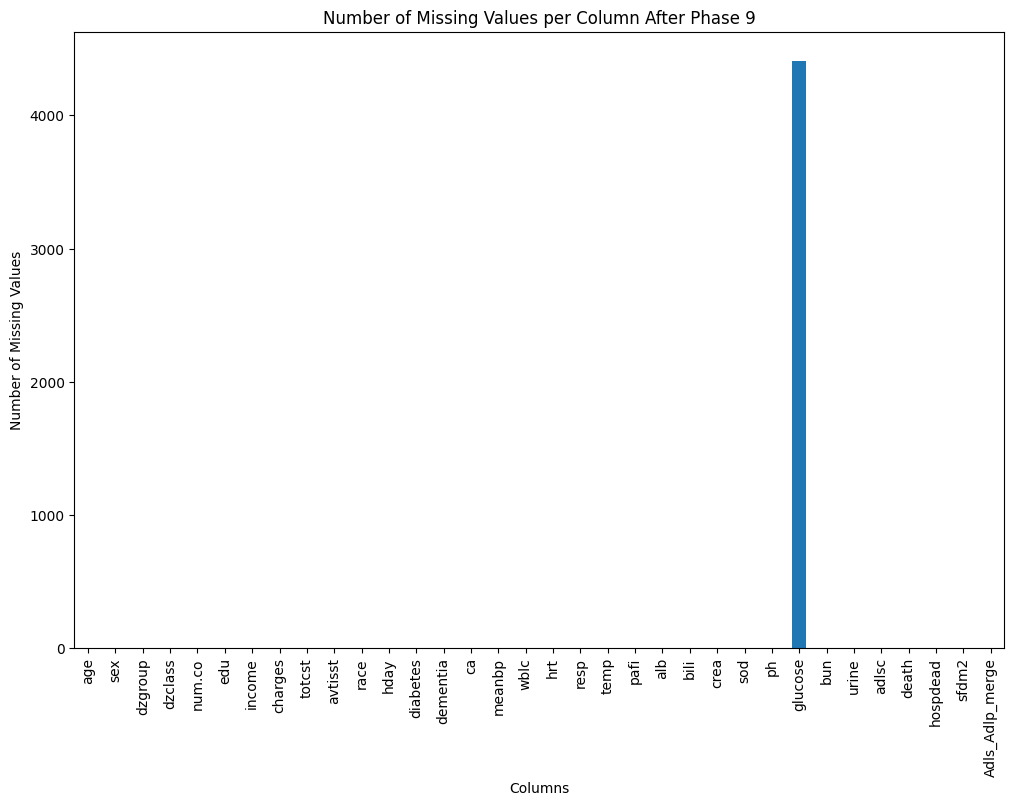

In [60]:
plt.figure(figsize=(12, 8))
na_summarised = df.isna().sum()
na_summarised.plot(kind='bar')

plt.title('Number of Missing Values per Column After Phase 9')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

In [61]:
num_filas_con_na_p9= df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p9}, the percentage of rows with na's is {(num_filas_con_na_p9/df.shape[0])*100}")

Number of rows with at least one NA: 4408, the percentage of rows with na's is 50.039732092178454


In [62]:
new_row = pd.DataFrame({
    'Phase': [9],
    'Atleast_1NA': [num_filas_con_na_p9],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

-  **Phase 10: Glucose**

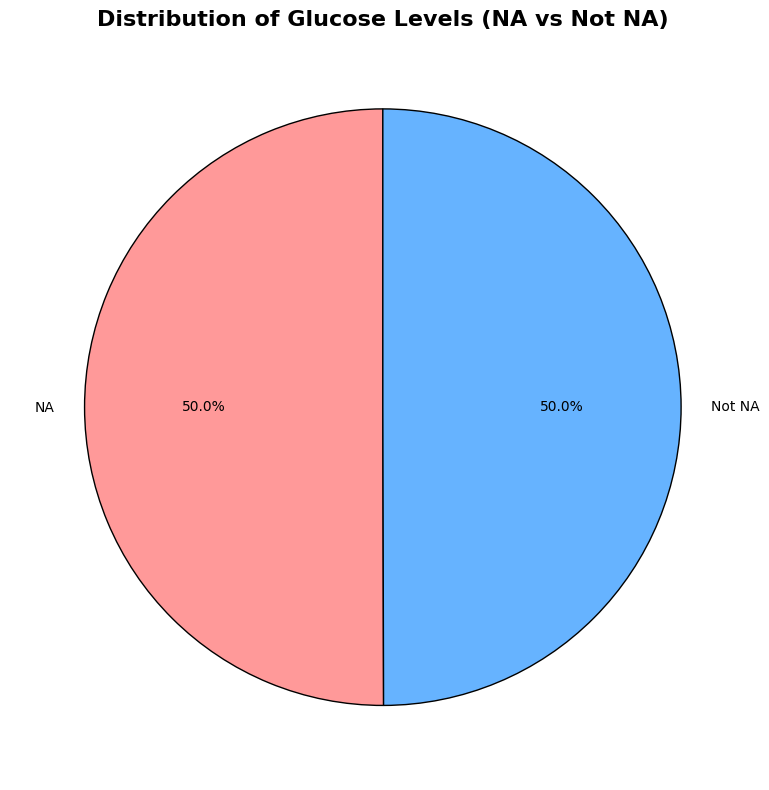

In [63]:
glucose_status = df['glucose'].isna().replace({True: 'NA', False: 'Not NA'})

# Create the pie chart
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
glucose_status.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'], startangle=90, wedgeprops={'edgecolor': 'black', 'linewidth': 1})

# Add title
plt.title('Distribution of Glucose Levels (NA vs Not NA)', fontsize=16, weight='bold')

# Display the chart
plt.ylabel('')  # Hide y-axis label
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

We have decided to remove the column from the dataset because it contains 50% NA values. With such a high percentage of missing data, imputing values ​​could introduce bias or distort the results, compromising the accuracy of the analysis. Imputation techniques, such as replacing with the mean or median, would not be appropriate in this case, as they could introduce noise and affect the quality of the predictive models. By removing the column, we ensure that the data used is as complete and representative as possible, ensuring the integrity and reliability of subsequent analyses.

In [64]:
df = df.drop(columns='glucose')

In [65]:
num_filas_con_na_p10= df.isna().any(axis=1).sum()
print(f"Number of rows with at least one NA: {num_filas_con_na_p10}, the percentage of rows with na's is {(num_filas_con_na_p10/df.shape[0])*100}")

Number of rows with at least one NA: 0, the percentage of rows with na's is 0.0


In [66]:
new_row = pd.DataFrame({
    'Phase': [10],
    'Atleast_1NA': [num_filas_con_na_p10],
    'Num_columns': [df.shape[1]],
    'Num_rows': [df.shape[0]],
    'Num_cells': [df.shape[1] * df.shape[0]]
})

# Concatenate the new row to the data_cleaning_evaluation DataFrame
data_cleaning_evaluation = pd.concat([data_cleaning_evaluation, new_row], ignore_index=True)

## 🛑 Visualization of how each phase of data cleaning has affected the structure of the df

In [67]:
data_cleaning_evaluation.set_index('Phase', inplace=True)
data_cleaning_evaluation


,Atleast_1NA,Num_columns,Num_rows,Num_cells
Phase,,,,
0,8799,45,9105,409725
1,8733,36,9105,327780
2,8425,36,9105,327780
3,8300,36,8980,323280
4,8129,36,8980,323280
5,8108,36,8980,323280
6,6176,35,8980,314300
7,5645,34,8980,305320
8,5474,34,8809,299506


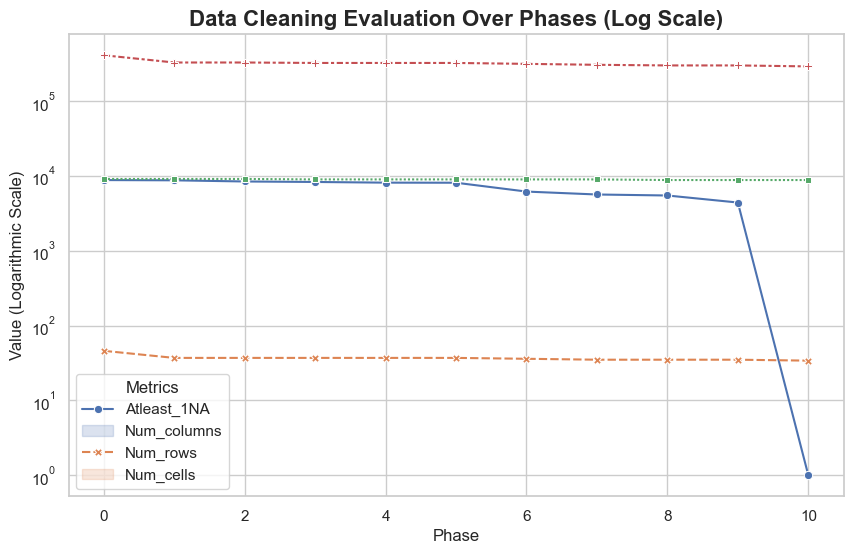

In [68]:
# Add a small constant (e.g., 1) to all values to avoid zero values in the data
data_cleaning_evaluation_adjusted = data_cleaning_evaluation + 1

# Set the Seaborn style
sns.set(style="whitegrid")  # Background with grid

# Create the line plot with Seaborn
plt.figure(figsize=(10, 6))
sns.lineplot(data=data_cleaning_evaluation_adjusted, markers=True)

# Customize title and labels
plt.title("Data Cleaning Evaluation Over Phases (Log Scale)", fontsize=16, fontweight='bold')
plt.xlabel("Phase", fontsize=12)
plt.ylabel("Value (Logarithmic Scale)", fontsize=12)

# Set the y-axis to a logarithmic scale
plt.yscale('log')

# Add a legend to identify each line
plt.legend(title='Metrics', labels=data_cleaning_evaluation.columns, loc='lower left')

# Show the plot
plt.show()

In [70]:
df.to_csv("/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataCleaned.csv")